# 02 EDA 

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("C:/Users/Siddhesh/Downloads/bank-customer-churn/data/raw/bank_churn.csv")

df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [9]:
overall = df["Exited"].mean()

print(f"Overall Churn Rate: {overall:.2%}")

Overall Churn Rate: 20.37%


In [10]:
def churn_by(col, order=None):
    t = df.groupby(col)["Exited"].agg(
        rate="mean",
        n="size"
    ).reset_index()

    ax = sns.barplot(data=t, x=col, y="rate", order=order)
    ax.axhline(overall, ls="--", c="grey")

    for i, r in t.iterrows():
        ax.text(i, r.rate, f"n={r.n}", ha="center", va="bottom", fontsize=8)

    plt.title(f"Churn Rate by {col}")
    plt.ylabel("Churn Rate")
    plt.xlabel(col)
    plt.xticks(rotation=30)
    plt.show()

    return t

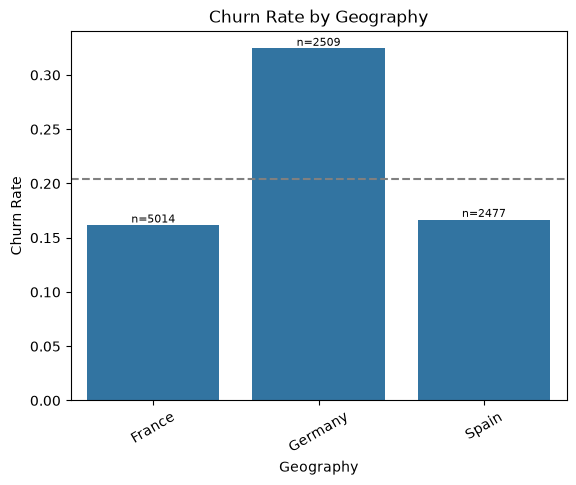

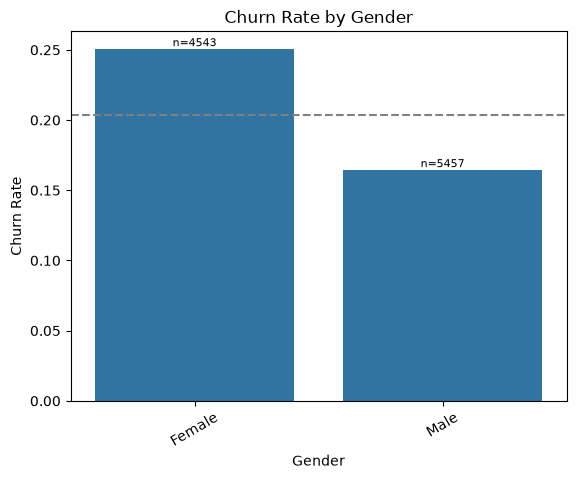

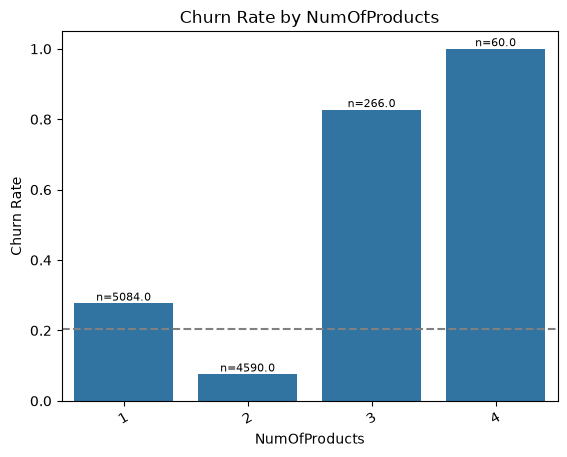

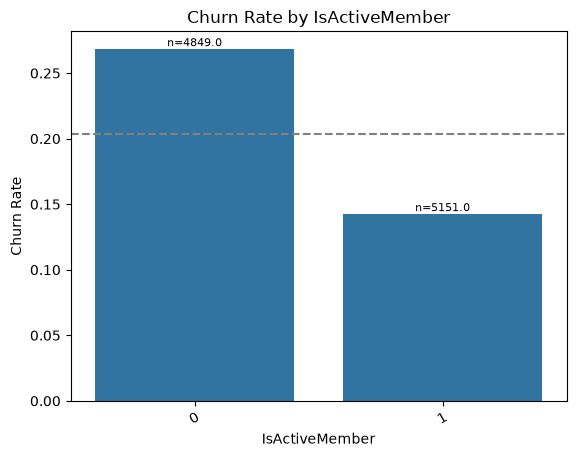

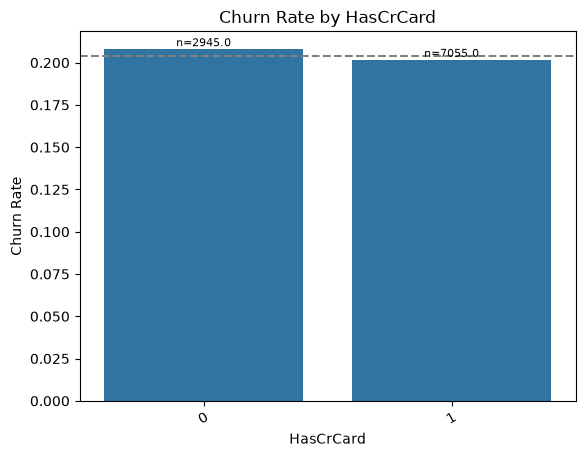

In [11]:
for c in ["Geography", "Gender", "NumOfProducts",
          "IsActiveMember", "HasCrCard"]:
    churn_by(c)